# Chapitre 6 - Cours 3 : points chauds et routage des requêtes

Les cours 1 et 2 ont réparti des **clés** équitablement. Ce notebook aborde deux
questions qui restent : que faire quand quelques clés reçoivent l'essentiel des
**requêtes** (le compte d'une célébrité, un message devenu viral) ? Et comment une
requête trouve-t-elle la partition, donc le nœud, qui détient sa
clé, alors même que les morceaux se déplacent ? Il couvre les sections *Skewed Workloads
and Relieving Hot Spots* et *Request Routing* (avec *Parallel Query Execution*).

**Plan.**

1. Le hachage répartit les clés, pas la charge : requêtes en loi de Zipf.
2. La célébrité : une clé chaude qui dure quelques heures.
3. Saler les clés chaudes : éclater les écritures, payer à la lecture.
4. Isoler une clé chaude, et distinguer lectures et écritures.
5. Trois façons de router une requête.
6. Qui détient la carte ? Coordinateur, notifications et diffusion épidémique.
7. Les requêtes qui touchent tous les morceaux : exécution parallèle.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Le hachage répartit les clés, pas la charge (section *Skewed Workloads and Relieving Hot Spots*)

Le hachage garantit que chaque morceau reçoit à peu près **le même nombre de clés**. Mais
si certaines clés sont beaucoup plus demandées que d'autres, la **charge** reste
déséquilibrée. Les popularités réelles suivent souvent une **loi de Zipf** : la clé de
rang $r$ reçoit une part proportionnelle à $1/r^s$. Avec $s = 1$ et 100 000 clés, la clé
la plus demandée attire à elle seule $1/H_{100\,000} \approx 8\,\%$ des requêtes
($H_n = \sum_{r \le n} 1/r \approx \ln n + 0{,}58$).

Calculons la charge exacte de 16 morceaux (clés placées par hachage) selon l'exposant
$s$.

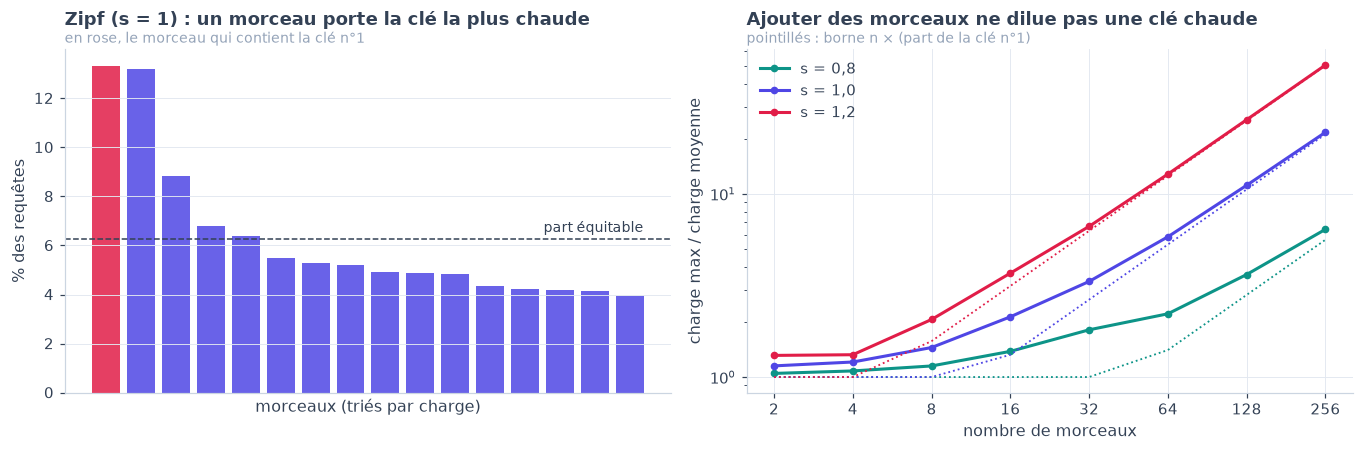

,part de la clé n°1,part des 100 premières,déséquilibre des morceaux
exposant s,,,
0.0,1.000e-05,0.001,1.026
0.6,4.031e-03,0.056,1.091
0.8,2.195e-02,0.179,1.381
1.0,8.271e-02,0.429,2.132
1.2,1.964e-01,0.708,3.692


In [2]:
N_KEYS, N_SH = 100_000, 16
keys = np.arange(N_KEYS)
shard_of_key = (P.hash_unit(keys) * N_SH).astype(int)
rows, loads_by_s = [], {}
for s in [0.0, 0.6, 0.8, 1.0, 1.2]:
    w = P.zipf_weights(N_KEYS, s)
    loads = P.shard_loads(shard_of_key, N_SH, weights=w)
    loads_by_s[s] = loads
    rows.append({"exposant s": s, "part de la clé n°1": w[0], "part des 100 premières": w[:100].sum(),
                 "déséquilibre des morceaux": P.imbalance(loads)})
zipf_tab = pd.DataFrame(rows).set_index("exposant s")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
order = np.argsort(-loads_by_s[1.0])
hot_shard = shard_of_key[0]
cols = [ROSE if i == hot_shard else INDIGO for i in order]
ax.bar(range(N_SH), loads_by_s[1.0][order] * 100, color=cols, alpha=0.85)
ax.axhline(100 / N_SH, color=SLATE, ls="--", lw=1); ax.text(15.4, 100 / N_SH + 0.3, "part équitable", ha="right", fontsize=9)
ax.set_xlabel("morceaux (triés par charge)"); ax.set_ylabel("% des requêtes")
ax.set_title("Zipf (s = 1) : un morceau porte la clé la plus chaude")
subtitle(ax, "en rose, le morceau qui contient la clé n°1")
ax.set_xticks([])
ax = axes[1]
ns = [2, 4, 8, 16, 32, 64, 128, 256]
for s, c in [(0.8, TEAL), (1.0, INDIGO), (1.2, ROSE)]:
    w = P.zipf_weights(N_KEYS, s)
    imb = [P.imbalance(P.shard_loads((P.hash_unit(keys) * n).astype(int), n, weights=w)) for n in ns]
    ax.plot(ns, imb, "o-", color=c, ms=4, label=f"s = {s}".replace(".", ","))
    ax.plot(ns, np.maximum(1, w[0] * np.array(ns)), ":", color=c, lw=1.2)
ax.set_xscale("log", base=2); ax.set_xticks(ns); ax.set_xticklabels(ns); ax.set_yscale("log")
ax.set_xlabel("nombre de morceaux"); ax.set_ylabel("charge max / charge moyenne")
ax.set_title("Ajouter des morceaux ne dilue pas une clé chaude")
subtitle(ax, "pointillés : borne n × (part de la clé n°1)")
ax.legend()
plt.tight_layout(); plt.show()
zipf_tab

Avec $s = 1$, le morceau qui contient la clé n°1 reçoit environ 13 % des requêtes, plus du
double de sa part équitable (6,25 %). Surtout, le graphique de droite montre que
**multiplier les morceaux n'y change rien** : la clé n°1 ne peut pas être coupée, si bien
que son morceau porte au moins $w_1$ de la charge totale, et le déséquilibre croît comme
$n \times w_1$ (pointillés). Avec 256 morceaux et $s = 1{,}2$, le morceau chaud reçoit
environ 50 fois la moyenne. Le hachage cohérent, si parfait soit-il, ne règle pas ce problème.

> **À retenir.** Le hachage équilibre le nombre de clés, pas leur popularité. Une clé
> chaude fixe un plancher de charge à son morceau, que l'ajout de nœuds ne fait pas
> baisser : $\text{déséquilibre} \ge n \cdot w_1$.